# Session 13: Introduction to Machine Learning

**Learning goals:**

- Explain how machine learning learns from examples.
- Distinguish supervised and unsupervised learning, and regression, classification and clustering.
- Follow a scikit-learn workflow and identify the main functions at each step.
- Describe common regression and classification methods and interpret their evaluation metrics.
- Build and evaluate models for California housing values and handwritten MNIST digits.

**Prerequisites:**

- Python variables and functions
- NumPy arrays
- pandas DataFrames
- Basic plotting
- Data cleaning from earlier sessions

This notebook uses practical explanations rather than mathematical derivations.

**Setup:** An existing Jupyter-compatible Python environment with Python 3.10+ with `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. 
Install packages from a terminal:

```bash
python -m pip install numpy pandas matplotlib scikit-learn
```

## Outline

1. What is machine learning?
2. Supervised vs unsupervised learning
3. Regression vs classification vs clustering
4. Python library: scikit-learn
5. ML workflow with scikit-learn
6. Regression & classification methods and evaluation metrics
7. Case Study — California Housing Regression
8. Case Study — MNIST Digit Classification

## 1. What Is Machine Learning?

**Machine learning (ML)** is a part of artificial intelligence in which a model learns patterns from examples and uses those patterns on new inputs. People choose the problem, the data, the learning method and the measures of success.

For example, a spam classifier learns from emails labelled `spam` or `not spam`. A housing model learns from property-related features and recorded values.

![Examples train a model that predicts outcomes for new inputs.](images/machine-learning-basics.svg)

- **Training** means learning from examples using `fit()`.
- **Inference** means using the fitted model through `predict()`.
- **Evaluation** checks whether predictions are useful on examples held out from training.

## 2. Supervised vs Unsupervised Learning

**Supervised learning** uses labelled examples; **unsupervised learning** searches for structure without supplied targets.

![Supervised learning uses targets; unsupervised learning discovers structure.](images/supervised-vs-unsupervised.svg)

| Aspect | Supervised learning | Unsupervised learning |
|---|---|---|
| Training inputs | Features `X` and known targets `y` | Features `X`, without supplied targets |
| Purpose | Learn to predict a known outcome | Discover structure in the data |
| Common tasks | Regression, classification | Clustering, dimensionality reduction |
| Example | Predict renewal using labelled customer records | Group customers by purchasing patterns |
| Typical fitting interface | `model.fit(X_train, y_train)` | `model.fit(X)` |

## 3. Regression vs Classification vs Clustering

![Regression predicts values, classification predicts known classes, and clustering discovers groups.](images/regression-classification-clustering-principle.svg)

| Task | Learning type | Output | Example |
|---|---|---|---|
| Regression | Supervised | A numeric quantity | House value, delivery time |
| Classification | Supervised | A predefined class | Spam/not spam; digit 0–9 |
| Clustering | Unsupervised | A discovered group | Groups of similar customers |

**Quick decision rules:**

- Predict a continuous number → **regression**.
- Predict one of several known labels → **classification**.
- Discover groups without known labels → **clustering**.

## 4. Python Library: scikit-learn

[`scikit-learn`](https://scikit-learn.org/stable/index.html) is an open-source Python machine learning library for supervised and unsupervised learning. It provides a consistent estimator interface as well as tools for preprocessing, model selection, pipelines and evaluation. This means that many different models can use the same core pattern: prepare data, call `fit`, produce predictions and evaluate the result.


Install the package as **`scikit-learn`** and import it as **`sklearn`**. It provides models, preprocessing tools, data splitting, model selection and evaluation functions.

| Module | Purpose | Examples |
|---|---|---|
| `sklearn.model_selection` | Split data | `train_test_split` |
| `sklearn.impute` | Fill missing feature values | `SimpleImputer` |
| `sklearn.preprocessing` | Scale and encode features | `StandardScaler`, `OneHotEncoder` |
| `sklearn.compose` | Process different columns or transform a target | `ColumnTransformer`, `TransformedTargetRegressor` |
| `sklearn.pipeline` | Combine preprocessing and a model | `Pipeline`, `make_pipeline` |
| `sklearn.linear_model` | Linear models | `LinearRegression`, `LogisticRegression` |
| `sklearn.neural_network` | Feed-forward neural networks | `MLPRegressor`, `MLPClassifier` |
| `sklearn.metrics` | Measure prediction quality | `mean_absolute_error`, `accuracy_score` |

[Official scikit-learn getting started guide](https://scikit-learn.org/stable/getting_started.html)

## 5. ML Workflow with scikit-learn

![Seven stages: inspect, define X and y, split, build pipeline, fit, predict, evaluate.](images/scikit-learn-workflow-labelled.png)

**Example: Celsius to Fahrenheit Linear Regression.** Predict Fahrenheit from Celsius using 25 synthetic temperature pairs in `sample_data/celsius_fahrenheit_noisy.csv`.

### Step 1 — Load and inspect the data

Load the CSV with `pd.read_csv()`. Check sample rows, column types and missing values with `head()`, `info()` and `isna().sum()`. Plot Celsius against Fahrenheit to inspect the relationship.

,celsius,fahrenheit
0,-20,-3.7
1,-15,5.1
2,-10,13.6
3,-5,23.3
4,0,31.4


<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   celsius     25 non-null     int64  
 1   fahrenheit  25 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes
Missing values:
celsius       0
fahrenheit    0
dtype: int64


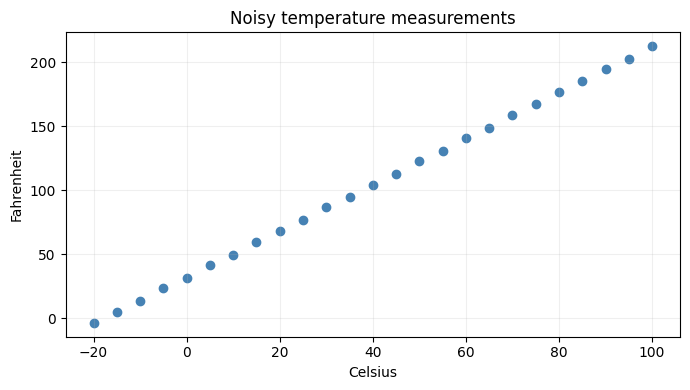

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

session_folder = 'Session13 Introduction to Machine Learning'
candidate_folders = [
    Path.cwd(),
    Path.cwd() / session_folder,
    Path.cwd() / 'LAP and Learning Materials' / session_folder,
]
BASE_DIR = next((folder for folder in candidate_folders
                 if (folder / 'sample_data/celsius_fahrenheit_noisy.csv').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('Open the notebook from the Session13 folder, LAP and Learning Materials, or DA_LAP.')
DATA_DIR = BASE_DIR / 'sample_data'
IMAGE_DIR = BASE_DIR / 'images'
IMAGE_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

temperature = pd.read_csv(DATA_DIR / 'celsius_fahrenheit_noisy.csv')
display(temperature.head())
temperature.info()
print('Missing values:')
print(temperature.isna().sum())

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(temperature['celsius'], temperature['fahrenheit'], color='steelblue')
ax.set(title='Noisy temperature measurements', xlabel='Celsius', ylabel='Fahrenheit')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'session13-temperature-data.png', dpi=150)
plt.show()

### Step 2 — Define features `X` and target `y`

Use `celsius` as the input and `fahrenheit` as the target. Double brackets keep `X` two-dimensional; single brackets make `y` a Series.

In [2]:
X_temperature = temperature[['celsius']]
y_temperature = temperature['fahrenheit']
print('X shape:', X_temperature.shape)
print('y shape:', y_temperature.shape)
display(X_temperature.head(3))

X shape: (25, 1)
y shape: (25,)


,celsius
0,-20
1,-15
2,-10


### Step 3 — Split into training and test data

Use `train_test_split()` to reserve 20% for testing. Set `random_state=42` to reproduce the split. Split before fitting preprocessing.

In [3]:
from sklearn.model_selection import train_test_split

X_temp_train, X_temp_test, y_temp_train, y_temp_test = train_test_split(
    X_temperature, y_temperature, test_size=0.2, random_state=RANDOM_STATE,
)
print('Training examples:', len(X_temp_train))
print('Test examples:', len(X_temp_test))

Training examples: 20
Test examples: 5


### Step 4 — Build a preprocessing and model pipeline

Use `make_pipeline()` to combine `StandardScaler()` and `LinearRegression()`. Scaling is optional for this example; it demonstrates how preprocessing and modelling work together.

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

temperature_model = make_pipeline(
    StandardScaler(),
    LinearRegression(),
)
temperature_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None


### Step 5 — Fit the model

Call `fit(X_temp_train, y_temp_train)` to train the scaler and regression model using training data only.

In [5]:
# Train both pipeline steps using only the training partition.
temperature_model.fit(X_temp_train, y_temp_train)
print('The scaler and linear regression model have been fitted.')

The scaler and linear regression model have been fitted.


### Step 6 — Produce predictions

Call `predict(X_temp_test)` to predict Fahrenheit for the test readings. For new inputs, use a DataFrame with the same `celsius` column.

In [6]:
temp_test_predictions = temperature_model.predict(X_temp_test)
temperature_predictions = X_temp_test.copy()
temperature_predictions['Actual Fahrenheit'] = y_temp_test
temperature_predictions['Predicted Fahrenheit'] = temp_test_predictions
display(temperature_predictions.sort_values('celsius').round(2))

new_temperatures = pd.DataFrame({'celsius': [0.0, 25.0, 100.0]})
new_temperatures['Predicted Fahrenheit'] = temperature_model.predict(new_temperatures)
display(new_temperatures.round(2))

,celsius,Actual Fahrenheit,Predicted Fahrenheit
0,-20,-3.7,-4.08
8,20,68.4,68.04
11,35,94.5,95.09
16,60,140.3,140.17
23,95,202.7,203.28


,celsius,Predicted Fahrenheit
0,0.0,31.98
1,25.0,77.06
2,100.0,212.30


### Step 7 — Evaluate and interpret the result

Compare test predictions with actual readings using `mean_absolute_error()`, `mean_squared_error()` and `r2_score()`. Use `np.sqrt()` to convert MSE to RMSE. Compare with a `DummyRegressor` mean baseline and plot the learned line.

,MAE (°F),RMSE (°F),R²
Model,,,
Linear regression,0.409,0.444,1.000
Mean baseline,57.762,69.365,-0.004


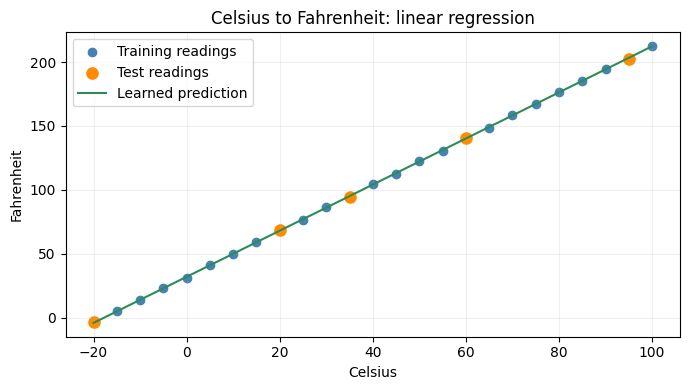

Average test error: 0.41 °F; mean-baseline error: 57.76 °F.


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

temperature_baseline = DummyRegressor(strategy='mean')
temperature_baseline.fit(X_temp_train, y_temp_train)
temp_baseline_predictions = temperature_baseline.predict(X_temp_test)

temperature_results = pd.DataFrame([
    {
        'Model': name,
        'MAE (°F)': mean_absolute_error(y_temp_test, predictions),
        'RMSE (°F)': np.sqrt(mean_squared_error(y_temp_test, predictions)),
        'R²': r2_score(y_temp_test, predictions),
    }
    for name, predictions in [
        ('Linear regression', temp_test_predictions),
        ('Mean baseline', temp_baseline_predictions),
    ]
]).set_index('Model')
display(temperature_results.round(3))

line_inputs = pd.DataFrame({'celsius': np.linspace(X_temperature['celsius'].min(),
                                                X_temperature['celsius'].max(), 100)})
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_temp_train['celsius'], y_temp_train, label='Training readings', color='steelblue')
ax.scatter(X_temp_test['celsius'], y_temp_test, label='Test readings', color='darkorange', s=65)
ax.plot(line_inputs['celsius'], temperature_model.predict(line_inputs),
        label='Learned prediction', color='seagreen')
ax.set(title='Celsius to Fahrenheit: linear regression', xlabel='Celsius', ylabel='Fahrenheit')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'session13-temperature-regression.png', dpi=150)
plt.show()

temp_mae = mean_absolute_error(y_temp_test, temp_test_predictions)
baseline_mae = mean_absolute_error(y_temp_test, temp_baseline_predictions)
print(f'Average test error: {temp_mae:.2f} °F; mean-baseline error: {baseline_mae:.2f} °F.')

Small measurement noise means predictions will not match every reading exactly. Lower test MAE than the mean baseline shows that Celsius helps predict Fahrenheit. The test set contains only five readings.

[Official scikit-learn workflow examples](https://scikit-learn.org/stable/getting_started.html)

## 6. Regression & Classification Methods and Evaluation Metrics

### 6.1 Common ML methods

- **Linear models:** `LinearRegression`, `Ridge`, `Lasso` for regression; `LogisticRegression` for classification. [scikit-learn: Linear models](https://scikit-learn.org/stable/modules/linear_model.html)
- **K-nearest neighbours (KNN):** `KNeighborsRegressor`, `KNeighborsClassifier`. [scikit-learn: Nearest neighbours](https://scikit-learn.org/stable/modules/neighbors.html)
- **Decision trees:** `DecisionTreeRegressor`, `DecisionTreeClassifier`. [scikit-learn: Decision trees](https://scikit-learn.org/stable/modules/tree.html)
- **Random forests:** `RandomForestRegressor`, `RandomForestClassifier`. [scikit-learn: Random forests](https://scikit-learn.org/stable/modules/ensemble.html#forest)
- **Gradient boosting:** `GradientBoostingRegressor`, `GradientBoostingClassifier`. [scikit-learn: Gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)
- **Multilayer perceptron (MLP):** `MLPRegressor`, `MLPClassifier`. [scikit-learn: Neural networks](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)

### 6.2 Regression evaluation metrics

Compare predictions with actual numeric targets on held-out observations. Report errors in meaningful units alongside a baseline.

| Metric | Plain-language interpretation | Better direction | Main function |
|---|---|---|---|
| MAE | Mean Absolute Error | Lower; 0 is perfect | `mean_absolute_error(y_true, y_pred)` |
| MSE | Mean Squared Error | Lower; 0 is perfect | `mean_squared_error(y_true, y_pred)` |
| RMSE | Root Mean Squared Error | Lower; 0 is perfect | `root_mean_squared_error(y_true, y_pred)`; or `np.sqrt(mean_squared_error(...))` |
| R² | Fit relative to the mean baseline | Higher; 1 is perfect | `r2_score(y_true, y_pred)` |

For a nonconstant evaluation target, **R² = 0** means the same squared error as predicting that set's mean; **negative R²** means worse performance. R² is not a percentage of correct predictions, and there is no universal “good” threshold.

### 6.3 Classification evaluation metrics

| Metric | Plain-language interpretation | Better direction | Main function |
|---|---|---|---|
| Accuracy | Proportion of correct predictions | Higher; 1 is perfect | `accuracy_score()` |
| Precision | Correct predictions among predicted positives | Higher; 1 is perfect | `precision_score()` |
| Recall | Positives found among actual positives | Higher; 1 is perfect | `recall_score()` |
| F1 | Balance of precision and recall | Higher; 1 is perfect | `f1_score()` |

For binary classification, specify the **positive class**. Precision focuses on false positives; recall focuses on missed positives.

[scikit-learn metrics guide](https://scikit-learn.org/stable/modules/model_evaluation.html)

## 7. Case Study — California Housing Regression

Predict `median_house_value` in US dollars using eight numeric features and **Random Forest Regression**. The local CSV contains 20,640 historical census block groups. Omit `ocean_proximity` for this example. Keep the target in dollars; no unit conversion is needed.

[scikit-learn: Random forests](https://scikit-learn.org/stable/modules/ensemble.html#forest)

### 7.1 Load and inspect

Load the CSV with `pd.read_csv()`. Check the first rows and missing values.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

housing = pd.read_csv(DATA_DIR / 'california_housing.csv')
print('Rows and columns:', housing.shape)
display(housing.head(3))
print('Missing values:')
print(housing.isna().sum())

Rows and columns: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


### 7.2 Define features and split

Use eight numeric inputs and reserve 20% of rows for testing with `train_test_split()`.

In [9]:
housing = housing.dropna(subset=['median_house_value'])
housing_features = [
    'longitude', 'latitude', 'housing_median_age', 'total_rooms',
    'total_bedrooms', 'population', 'households', 'median_income',
]
X_house = housing[housing_features]
y_house = housing['median_house_value']
X_house_train, X_house_test, y_house_train, y_house_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=RANDOM_STATE,
)
print('Training:', X_house_train.shape)
print('Test:', X_house_test.shape)

Training: (16512, 8)
Test: (4128, 8)


### 7.3 Build and train Random Forest

`SimpleImputer()` fills missing inputs using training medians. `RandomForestRegressor(n_estimators=100)` combines 100 trees. `max_depth=16` limits tree depth. Trees do not require feature scaling. Call `fit()` on training data only.

In [10]:
house_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(n_estimators=100, max_depth=16, random_state=RANDOM_STATE),
)
house_model.fit(X_house_train, y_house_train)
print('Random Forest model fitted.')

Random Forest model fitted.


### 7.4 Predict and evaluate

Use `predict()` on test inputs. Report MAE and RMSE in dollars and R². Points closer to the diagonal have more accurate predictions.

,MAE ($),RMSE ($),R²
Random Forest,32449.058,50060.864,0.809


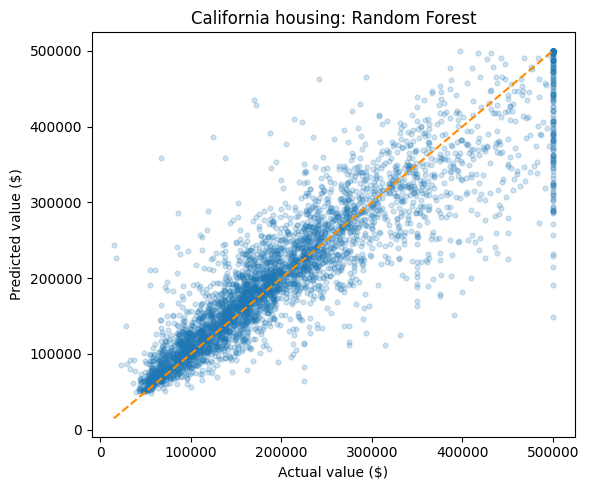

In [11]:
house_test_pred = house_model.predict(X_house_test)
house_results = pd.DataFrame([{
    'MAE ($)': mean_absolute_error(y_house_test, house_test_pred),
    'RMSE ($)': np.sqrt(mean_squared_error(y_house_test, house_test_pred)),
    'R²': r2_score(y_house_test, house_test_pred),
}], index=['Random Forest'])
display(house_results.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_house_test, house_test_pred, alpha=0.2, s=12)
limits = [y_house_test.min(), y_house_test.max()]
ax.plot(limits, limits, '--', color='darkorange')
ax.set(title='California housing: Random Forest',
       xlabel='Actual value ($)', ylabel='Predicted value ($)')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'session13-housing-evaluation.png', dpi=150)
plt.show()

MAE describes the average absolute error in dollars. RMSE gives large errors more influence. These test scores describe a random split of historical data; the capped target and geographic overlap limit conclusions about new regions or current prices.

## 8. Case Study — MNIST Digit Classification

Identify handwritten digits using an **MLP with one hidden layer**. The local CSV contains 6,000 images, with a label followed by 784 pixel values per row and no header. Use a stratified 3,000-image subset for classroom training.

[scikit-learn: MLP](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)

### 8.1 Load and inspect

Use `header=None` to retain the first image. Sample 3,000 rows with `stratify` to preserve digit proportions.

In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay,
)

mnist_columns = ['label'] + [f'pixel_{i}' for i in range(784)]
mnist = pd.read_csv(DATA_DIR / 'mnist_train_small.csv', header=None, names=mnist_columns)
mnist_subset, _ = train_test_split(
    mnist, train_size=3000, stratify=mnist['label'], random_state=RANDOM_STATE,
)
print('Local CSV shape:', mnist.shape)
print('Classroom subset shape:', mnist_subset.shape)

Local CSV shape: (6000, 785)
Classroom subset shape: (3000, 785)


### 8.2 Prepare pixels and split

Divide pixels by 255 to scale them to 0–1. Reserve 20% for testing with `stratify=y_digits`. Reshape rows to 28 × 28 only when displaying images.

Training: (2400, 784)
Test: (600, 784)


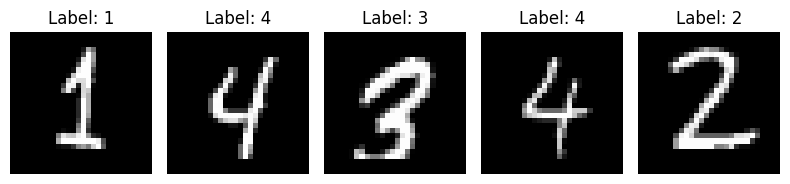

In [13]:
X_digits = mnist_subset.drop(columns='label').to_numpy(dtype=float) / 255.0
y_digits = mnist_subset['label'].to_numpy(dtype=int)
X_digit_train, X_digit_test, y_digit_train, y_digit_test = train_test_split(
    X_digits, y_digits, test_size=0.2, stratify=y_digits, random_state=RANDOM_STATE,
)
print('Training:', X_digit_train.shape)
print('Test:', X_digit_test.shape)

fig, axes = plt.subplots(1, 5, figsize=(8, 2))
for ax, pixels, label in zip(axes, X_digit_train[:5], y_digit_train[:5]):
    ax.imshow(pixels.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Label: {label}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'session13-mnist-examples.png', dpi=150)
plt.show()

### 8.3 Build and train the MLP

`hidden_layer_sizes=(64,)` creates one hidden layer with 64 neurons. `max_iter=100` limits training passes. `early_stopping=True` uses part of the training data to check progress and stop when improvement stalls.

In [14]:
digit_model = MLPClassifier(
    hidden_layer_sizes=(64,), batch_size=128, max_iter=100,
    early_stopping=True, random_state=RANDOM_STATE,
)
digit_model.fit(X_digit_train, y_digit_train)
print('Training passes:', digit_model.n_iter_)

Training passes: 33


### 8.4 Predict and evaluate

Use `predict()` to obtain test labels. Report Accuracy, Precision, Recall and F1; `average='macro'` gives each digit equal weight. In the confusion matrix, rows show actual digits and columns show predictions.

,Accuracy,Macro precision,Macro recall,Macro F1
"MLP (64,)",0.8967,0.8982,0.8967,0.8966


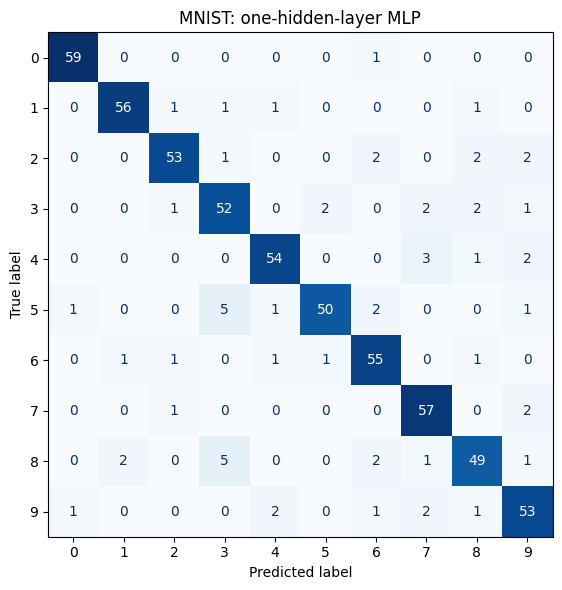

In [15]:
digit_test_pred = digit_model.predict(X_digit_test)
digit_results = pd.DataFrame([{
    'Accuracy': accuracy_score(y_digit_test, digit_test_pred),
    'Macro precision': precision_score(y_digit_test, digit_test_pred, average='macro', zero_division=0),
    'Macro recall': recall_score(y_digit_test, digit_test_pred, average='macro', zero_division=0),
    'Macro F1': f1_score(y_digit_test, digit_test_pred, average='macro', zero_division=0),
}], index=['MLP (64,)'])
display(digit_results.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_digit_test, digit_test_pred, labels=list(range(10)),
    cmap='Blues', colorbar=False, ax=ax,
)
ax.set_title('MNIST: one-hidden-layer MLP')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'session13-mnist-confusion-matrix.png', dpi=150)
plt.show()

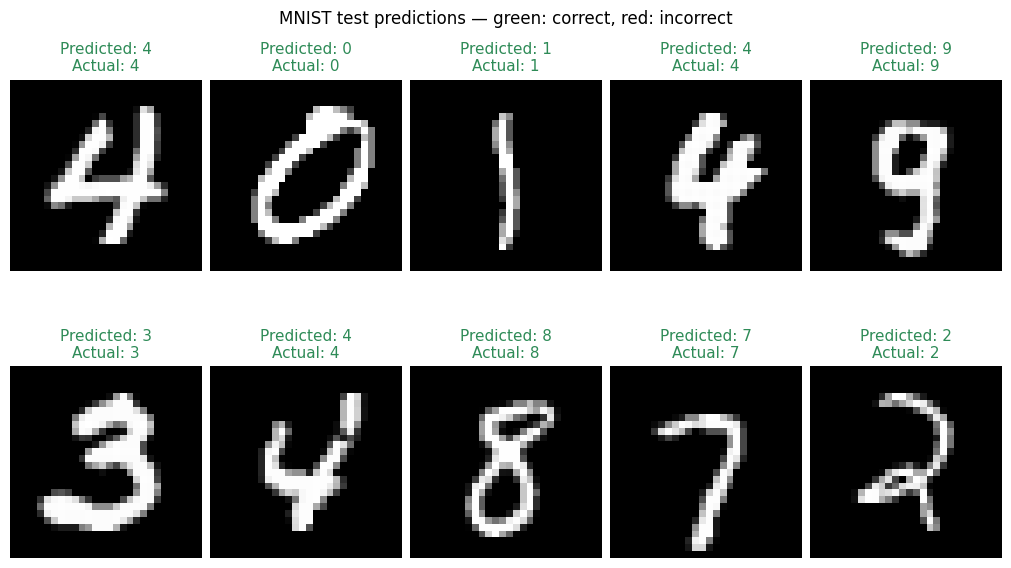

In [16]:
# Display ten test images with their predicted and actual labels.
fig, axes = plt.subplots(2, 5, figsize=(10, 6), layout='constrained')
for index, ax in enumerate(axes.flat):
    ax.imshow(X_digit_test[index].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    predicted = digit_test_pred[index]
    actual = y_digit_test[index]
    ax.set_title(f'Predicted: {predicted}\nActual: {actual}',
                 color='seagreen' if predicted == actual else 'crimson', fontsize=11)
    ax.axis('off')
fig.suptitle('MNIST test predictions — green: correct, red: incorrect')
plt.show()

`average='macro'` calculates Precision, Recall and F1 for each digit, then averages each metric with equal weight across all ten digits. Accuracy reports the proportion of correct predictions overall.

Higher scores indicate better test performance. Off-diagonal counts show which digits are confused. This classroom test split comes from the supplied training-source CSV; it is not the official MNIST benchmark test set.